# EDS 220 Assignment 4
## Task 2: Visualizing fire scars through false color
### Author: Kelly Morgan

The repository for this project can be found at [@kellyloveskelp](https://github.com/kellyloveskelp/eds220-hwk4) on GitHub.

In [1]:
# Import packages
import os              
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr   
import rioxarray as rioxr

### Fire perimeter data exploration

In [ ]:
# Perimeter data downloaded from class data folder
fp2 = os.path.join('data', 'land-cover-stats-data', 'Eaton_Perimeter_20250121', 'Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(fp2).to_crs("EPSG:4326")

fp3 = os.path.join('data', 'land-cover-stats-data', 'Palisades_Perimeter_20250121', 'Palisades_Perimeter_20250121.shp')
pali = gpd.read_file(fp3).to_crs("EPSG:4326")

In [3]:
eaton.head()

,OBJECTID,type,Shape__Are,Shape__Len,geometry
0,1,Heat Perimeter,2206.265625,270.199719,"POLYGON ((-118.10094 34.16681, -118.10090 34.1..."
1,2,Heat Perimeter,20710.207031,839.204218,"POLYGON ((-118.13596 34.17789, -118.13593 34.1..."
2,3,Heat Perimeter,3639.238281,250.304502,"POLYGON ((-118.15626 34.18045, -118.15643 34.1..."
3,4,Heat Perimeter,1464.550781,148.106792,"POLYGON ((-118.08442 34.18090, -118.08445 34.1..."
4,5,Heat Perimeter,4132.753906,247.960744,"POLYGON ((-118.15659 34.18148, -118.15659 34.1..."


In [4]:
print(type(eaton))
print(eaton.dtypes)

<class 'geopandas.geodataframe.GeoDataFrame'>
OBJECTID         int64
type            object
Shape__Are     float64
Shape__Len     float64
geometry      geometry
dtype: object


In [5]:
print(type(pali))
print(pali.dtypes)

<class 'geopandas.geodataframe.GeoDataFrame'>
OBJECTID         int64
type            object
Shape__Are     float64
Shape__Len     float64
geometry      geometry
dtype: object


In [ ]:
# Assert that CRS's match!
assert eaton.crs == pali.crs

In [ ]:
# Examine Eaton CRS details
print('CRS: ', eaton.crs)
print('Ellipsoid: ', eaton.crs.ellipsoid)
print('Datum: ', eaton.crs.datum)
print('Is geographic? ', eaton.crs.is_geographic)
print('Is projected? ', eaton.crs.is_projected)

Ellipsoid:  WGS 84
Datum:  World Geodetic System 1984 ensemble
Is geographic?  True
Is projected?  False


In [ ]:
# Examine Palisades CRS details
print('CRS: ', pali.crs)
print('Ellipsoid: ', pali.crs.ellipsoid)
print('Datum: ', pali.crs.datum)
print('Is geographic? ', pali.crs.is_geographic)
print('Is projected? ', pali.crs.is_projected)

Ellipsoid:  WGS 84
Datum:  World Geodetic System 1984 ensemble
Is geographic?  True
Is projected?  False


Summary: The Eaton and Palisades datasets share the same data types, column attributes, and CRS attributes. Both datasets use geographic coordinate system WGS 84, and CRS EPSG:4326.

### NetCDF data import and exploration

In [ ]:
# Read in the data
fp1 = os.path.join('data', 'landsat8-2025-02-23-palisades-eaton.nc')
landsat = xr.open_dataset(fp1)

In [12]:
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

In [13]:
print('CRS: ', landsat.rio.crs)
print('Height:', landsat.rio.height)
print('Width:', landsat.rio.width, '\n')
print('Dimensions:', landsat.dims)
print('Coordinates:', landsat.coords, '\n')

print('Spatial bounding box: ')
print(landsat.rio.bounds())

CRS:  None
Height: 1418
Width: 2742 

Dimensions: FrozenMappingWarningOnValuesAccess({'y': 1418, 'x': 2742})
Coordinates: Coordinates:
  * y        (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x        (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time     datetime64[ns] 8B ... 

Spatial bounding box: 
(334395.0, 3756525.0, 416655.0, 3799065.0)


Summary: The Landsat dataset is stored as a netCDF file containing x-y dimensions, coordinates, and five differnet color bands including RGB, SWIR, and NIR. The coordinates are stored as float numbers on the order of 10^5. There appears to be no CRS associated with the data.

### Restoring geospatial information

In [14]:
print('Is this a geospatial object?', landsat.rio.crs)

Is this a geospatial object? None


In [ ]:
# What is stored in "spatial_ref" ?
landsat['spatial_ref'].crs_wkt

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [16]:
landsat = landsat.rio.write_crs(landsat['spatial_ref'].crs_wkt)

In [ ]:
# Check new CRS !
print(landsat.rio.crs)

EPSG:32611


In [ ]:
# Transform Eaton and Palisade's CRS's to plot
eaton = eaton.to_crs(landsat.rio.crs)
pali = pali.to_crs(landsat.rio.crs)

In [ ]:
# Assert that *all* CRS's match!
assert eaton.crs == pali.crs == landsat.rio.crs

### True color image

In [23]:
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


<xarray.Dataset> Size: 12MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          (y, x) bool 4MB False False False False ... False False False
    green        (y, x) bool 4MB False False False False ... False False False
    blue         (y, x) bool 4MB False False False False ... False False False

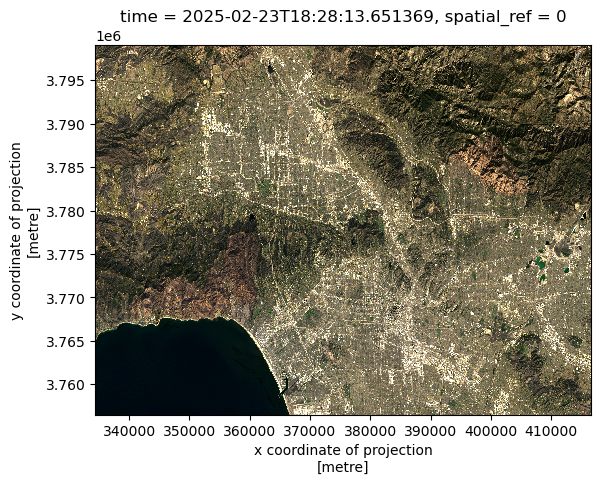

In [24]:
np.isnan(landsat[['red', 'green', 'blue']])

In [25]:
landsat = landsat.fillna(0)

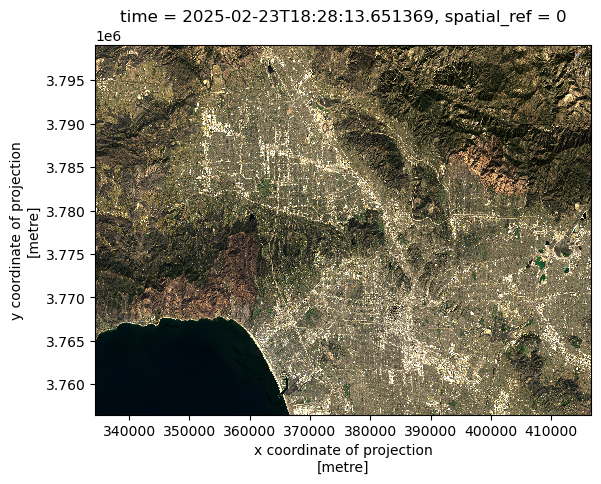

In [26]:
true_color = landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)
true_color

Explaination: The true color raster now plots with no error message! The original warning–– *"RuntimeWarning: invalid value encountered in cast xx = (xx * 255).astype(np.uint8)"*–– occured when the function `plot.imshow()` encountered Nan values that it could not plot. Applying `fillna(0)` assigns digital numbers to the NaN values that the raster plotting function can calculate.

### False color image

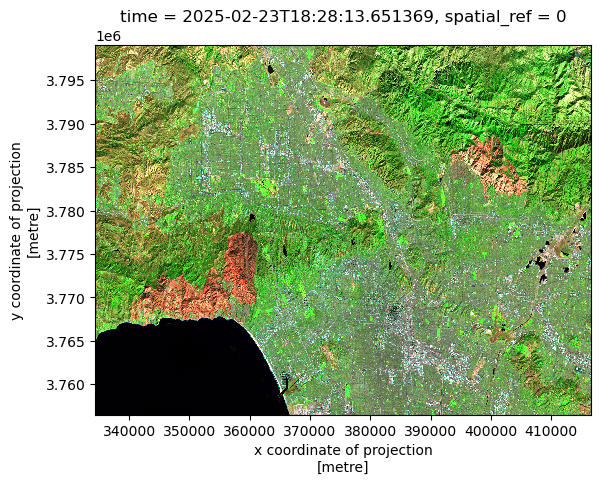

In [27]:
false_color = landsat[['swir22', 'nir08', 'red']].to_dataarray()
false_color.plot.imshow(robust=True)

## Map of fire scars over false-color

In [28]:
aspect_ratio = landsat.rio.width / landsat.rio.height # Raster aspect ratio

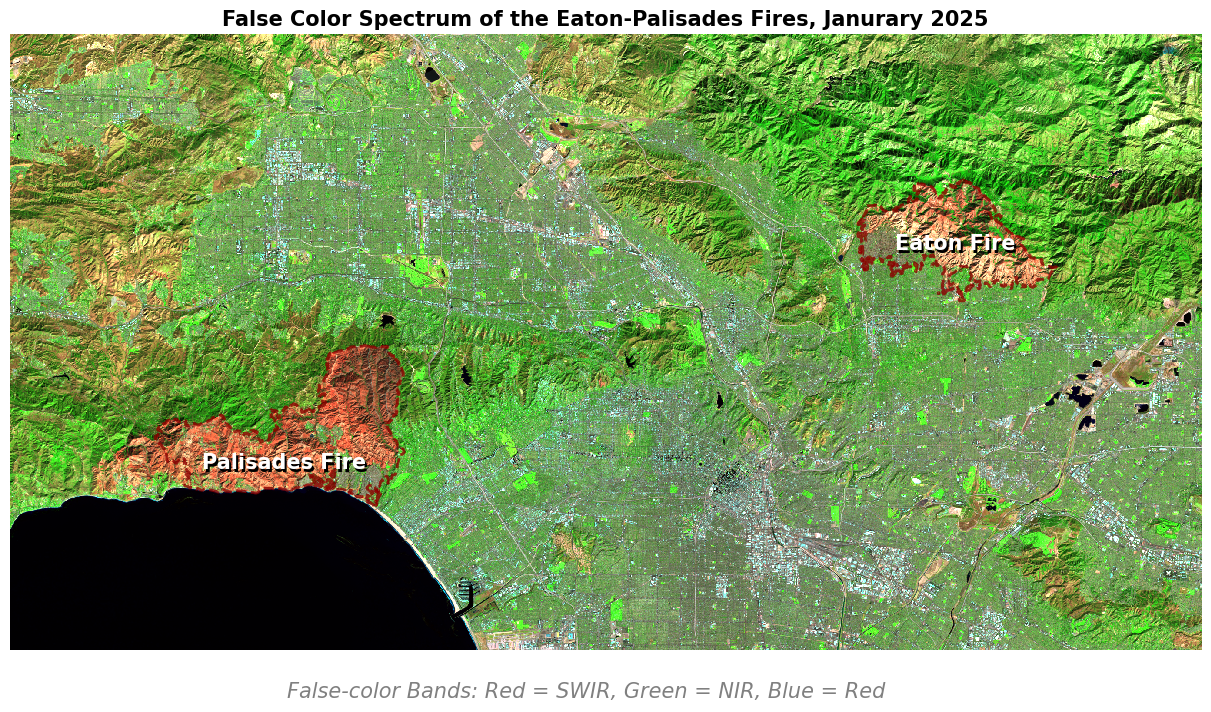

In [104]:
fig, ax = plt.subplots(figsize=(8*aspect_ratio, 8))
                       
false_color.plot.imshow(ax=ax, robust=True)

eaton.plot(ax=ax, 
           alpha = 0.8, 
           color = 'none', 
           edgecolor = "darkred",
           linewidth = 2, 
           linestyle ='--')

pali.plot(ax=ax, 
          alpha = 0.8, 
          color = 'none', 
          edgecolor = "darkred",
          linewidth = 2, 
          linestyle ='--')

# Coding white over black text lables to create drop shadow effect
# Not super smooth but gets the job done

ax.text(
    eaton.centroid.x[0] - 2900, 
    eaton.centroid.y[0] + 2800, 
    "Eaton Fire", 
    color = 'black',
    fontsize = 15, 
    fontweight = 'bold',
    ha='left'
    )
ax.text(
    pali.centroid.x[0] - 11900, 
    pali.centroid.y[0] + 2300, 
    "Palisades Fire", 
    color = 'black', 
    fontsize = 15, 
    fontweight = 'bold',
    ha='left')

ax.text(
    eaton.centroid.x[0] - 3000, 
    eaton.centroid.y[0] + 3000, 
    "Eaton Fire", 
    color = 'white',
    fontsize = 15, 
    fontweight = 'bold',
    ha='left'
    )
ax.text(
    pali.centroid.x[0] - 12000, 
    pali.centroid.y[0] + 2500, 
    "Palisades Fire", 
    color = 'white', 
    fontsize = 15, 
    fontweight = 'bold',
    ha='left')

ax.set_title('False Color Spectrum of the Eaton-Palisades Fires, Janurary 2025', fontsize = 15, fontweight = 'bold')

fig.text(
    0.5, 
    0.05,
    "False-color Bands: Red = SWIR, Green = NIR, Blue = Red",
    fontsize = 15,
    style = "italic",
    color = "grey",
    ha = "center"
         )

ax.axis('off')

plt.show()

### Map Analysis
The false-color rendition of Los Angeles Landsat imagery clearly visualizes the devasting impacts of the Eaton and Palisades fires of 2025. When SWIR and NIR are set to the red and green channels respectively, "plant-covered land is bright green, water is black, and bare earth ranges from tan to pink" (NASA Earth Observatory). The pink-redish hue of the land cover in Eaton and the Palisades indicate bare earth, in this case, exposed by fire. In the Landsat imagery, the Palisades fire appears as if it may have burned further than the estimated boundary displayed by ther red dashed line.